<a href="https://colab.research.google.com/github/sirinsultana741140-lgtm/heart-disease-prediction-and-patient-risk-analysis/blob/main/heart_disease_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
import warnings
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
zip_path = '/content/drive/MyDrive/archive (1).zip'

print(zip_path)

/content/drive/MyDrive/archive (1).zip


In [ ]:
import zipfile

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    print("Files inside the ZIP:")
    for file in zip_ref.namelist():
        print(file)

Files inside the ZIP:
heart_disease_dataset.csv


In [ ]:
import os
import zipfile

# Create a folder for the extracted dataset
dataset_folder = '/content/drive/MyDrive/Heart_Disease_Project'

os.makedirs(dataset_folder, exist_ok=True)

# Extract the ZIP
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(dataset_folder)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
for root, dirs, files in os.walk(dataset_folder):
    for file in files:
        print(os.path.join(root, file))

/content/drive/MyDrive/Heart_Disease_Project/heart_disease_dataset.csv


In [ ]:
import pandas as pd

csv_path = '/content/drive/MyDrive/Heart_Disease_Project/heart_disease_dataset.csv'

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()

,Age,Gender,Cholesterol,Blood Pressure,Heart Rate,Smoking,Alcohol Intake,Exercise Hours,Family History,Diabetes,Obesity,Stress Level,Blood Sugar,Exercise Induced Angina,Chest Pain Type,Heart Disease
0,75,Female,228,119,66,Current,Heavy,1,No,No,Yes,8,119,Yes,Atypical Angina,1
1,48,Male,204,165,62,Current,NaN,5,No,No,No,9,70,Yes,Typical Angina,0
2,53,Male,234,91,67,Never,Heavy,3,Yes,No,Yes,5,196,Yes,Atypical Angina,1
3,69,Female,192,90,72,Current,NaN,4,No,Yes,No,7,107,Yes,Non-anginal Pain,0
4,62,Female,172,163,93,Never,NaN,6,No,Yes,No,2,183,Yes,Asymptomatic,0


Display last five record

In [ ]:
df.tail()

,Age,Gender,Cholesterol,Blood Pressure,Heart Rate,Smoking,Alcohol Intake,Exercise Hours,Family History,Diabetes,Obesity,Stress Level,Blood Sugar,Exercise Induced Angina,Chest Pain Type,Heart Disease
995,56,Female,269,111,86,Never,Heavy,5,No,Yes,Yes,10,120,No,Non-anginal Pain,1
996,78,Female,334,145,76,Never,NaN,6,No,No,No,10,196,Yes,Typical Angina,1
997,79,Male,151,179,81,Never,Moderate,4,Yes,No,Yes,8,189,Yes,Asymptomatic,0
998,60,Female,326,151,68,Former,NaN,8,Yes,Yes,No,5,174,Yes,Atypical Angina,1
999,53,Male,226,116,82,Current,NaN,6,No,No,Yes,5,161,Yes,Asymptomatic,1


In [ ]:
print(df.shape)

(1000, 16)


Display column names

In [ ]:
print(df.columns)

Index(['Age', 'Gender', 'Cholesterol', 'Blood Pressure', 'Heart Rate',
       'Smoking', 'Alcohol Intake', 'Exercise Hours', 'Family History',
       'Diabetes', 'Obesity', 'Stress Level', 'Blood Sugar',
       'Exercise Induced Angina', 'Chest Pain Type', 'Heart Disease'],
      dtype='object')


Disply datatypes

In [ ]:
print(df.dtypes)

Age                         int64
Gender                     object
Cholesterol                 int64
Blood Pressure              int64
Heart Rate                  int64
Smoking                    object
Alcohol Intake             object
Exercise Hours              int64
Family History             object
Diabetes                   object
Obesity                    object
Stress Level                int64
Blood Sugar                 int64
Exercise Induced Angina    object
Chest Pain Type            object
Heart Disease               int64
dtype: object


Dataset information

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Age                      1000 non-null   int64 
 1   Gender                   1000 non-null   object
 2   Cholesterol              1000 non-null   int64 
 3   Blood Pressure           1000 non-null   int64 
 4   Heart Rate               1000 non-null   int64 
 5   Smoking                  1000 non-null   object
 6   Alcohol Intake           660 non-null    object
 7   Exercise Hours           1000 non-null   int64 
 8   Family History           1000 non-null   object
 9   Diabetes                 1000 non-null   object
 10  Obesity                  1000 non-null   object
 11  Stress Level             1000 non-null   int64 
 12  Blood Sugar              1000 non-null   int64 
 13  Exercise Induced Angina  1000 non-null   object
 14  Chest Pain Type          1000 non-null   

In [ ]:
df.describe()

,Age,Cholesterol,Blood Pressure,Heart Rate,Exercise Hours,Stress Level,Blood Sugar,Heart Disease
count,1000.000000,1000.000000,1000.0000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,52.293000,249.939000,135.2810,79.204000,4.529000,5.646000,134.941000,0.392000
std,15.727126,57.914673,26.3883,11.486092,2.934241,2.831024,36.699624,0.488441
min,25.000000,150.000000,90.0000,60.000000,0.000000,1.000000,70.000000,0.000000
25%,39.000000,200.000000,112.7500,70.000000,2.000000,3.000000,104.000000,0.000000
50%,52.000000,248.000000,136.0000,79.000000,4.500000,6.000000,135.000000,0.000000
75%,66.000000,299.000000,159.0000,89.000000,7.000000,8.000000,167.000000,1.000000
max,79.000000,349.000000,179.0000,99.000000,9.000000,10.000000,199.000000,1.000000


In [ ]:
print(df.describe(include="all"))

                Age  Gender  Cholesterol  Blood Pressure   Heart Rate Smoking  \
count   1000.000000    1000  1000.000000       1000.0000  1000.000000    1000   
unique          NaN       2          NaN             NaN          NaN       3   
top             NaN  Female          NaN             NaN          NaN   Never   
freq            NaN     503          NaN             NaN          NaN     338   
mean      52.293000     NaN   249.939000        135.2810    79.204000     NaN   
std       15.727126     NaN    57.914673         26.3883    11.486092     NaN   
min       25.000000     NaN   150.000000         90.0000    60.000000     NaN   
25%       39.000000     NaN   200.000000        112.7500    70.000000     NaN   
50%       52.000000     NaN   248.000000        136.0000    79.000000     NaN   
75%       66.000000     NaN   299.000000        159.0000    89.000000     NaN   
max       79.000000     NaN   349.000000        179.0000    99.000000     NaN   

       Alcohol Intake  Exer

In [ ]:
df.isnull().sum()

,0
Age,0
Gender,0
Cholesterol,0
Blood Pressure,0
Heart Rate,0
Smoking,0
Alcohol Intake,340
Exercise Hours,0
Family History,0
Diabetes,0


In [ ]:
print(df.isnull().sum().sum())

340


In [ ]:
df.duplicated().sum()

np.int64(0)

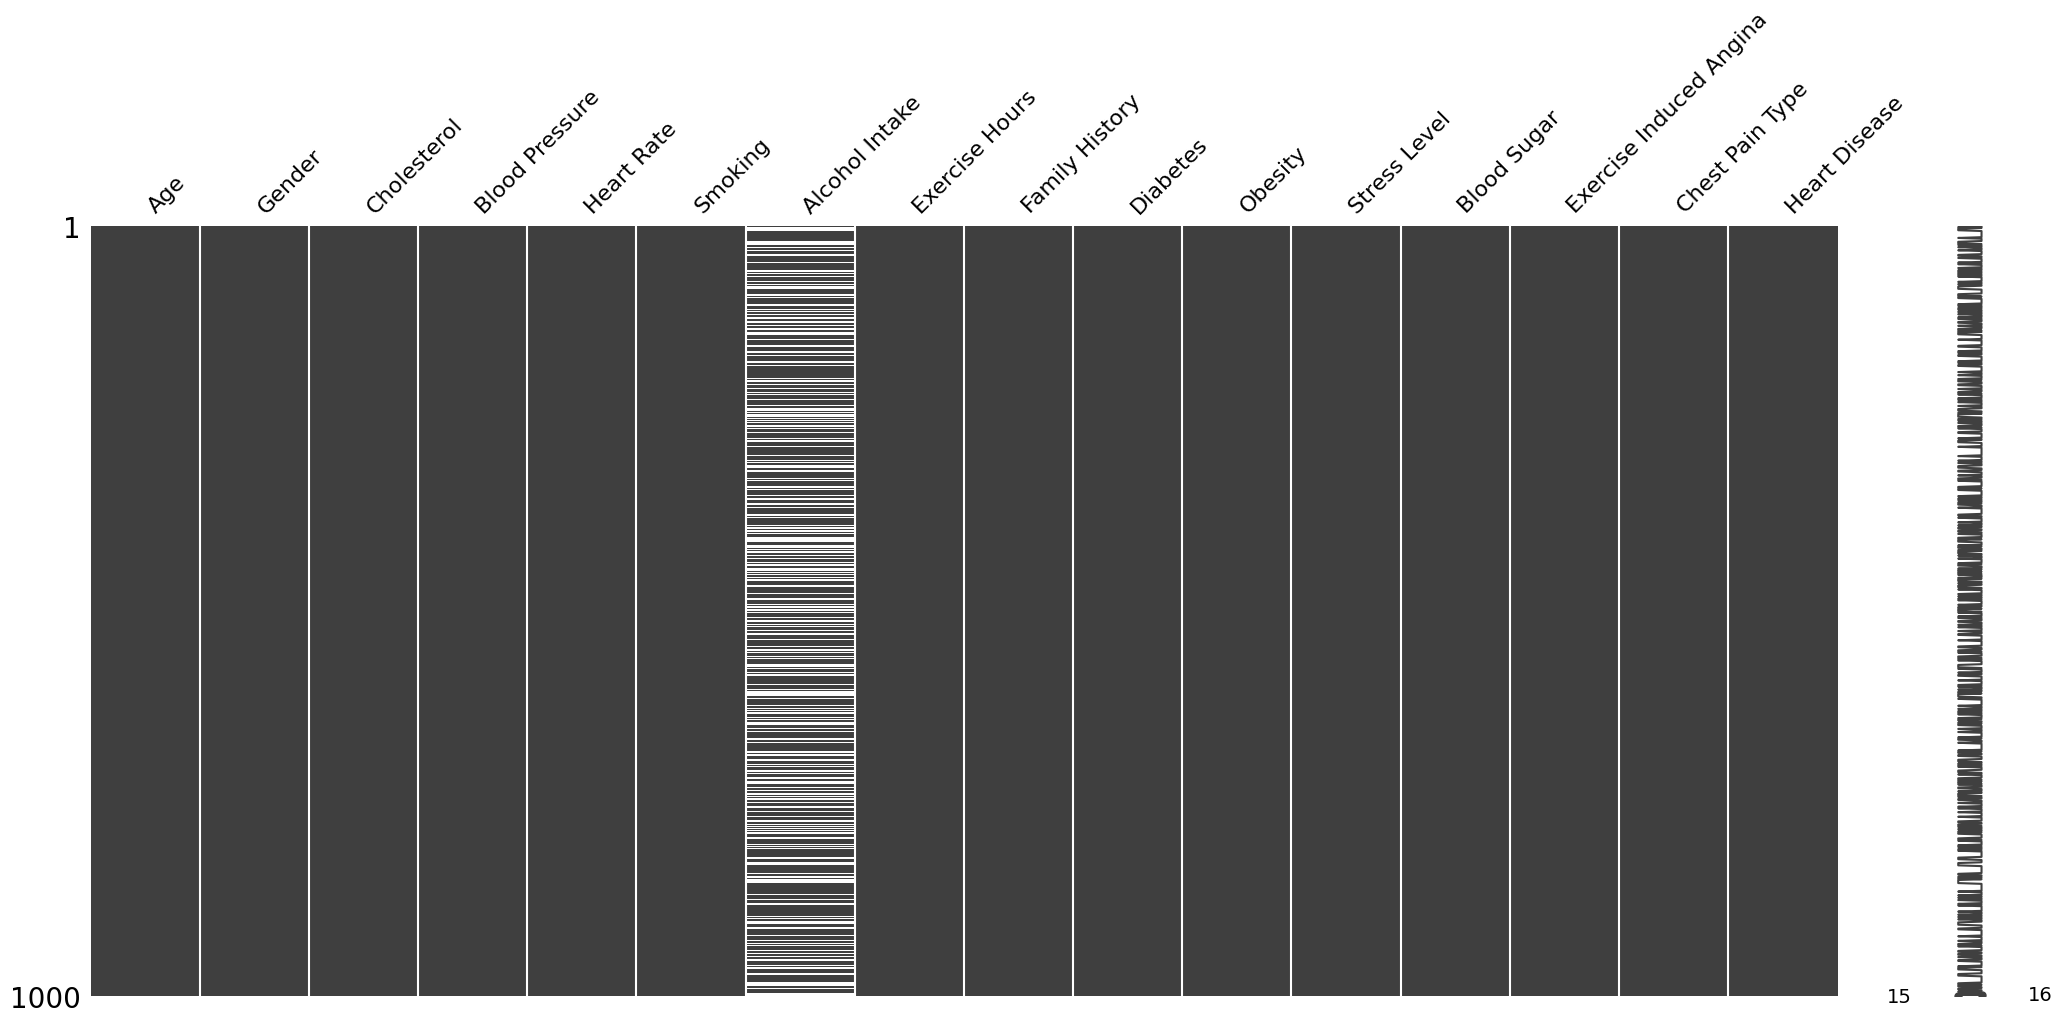

In [ ]:
msno.matrix(df)
plt.show()

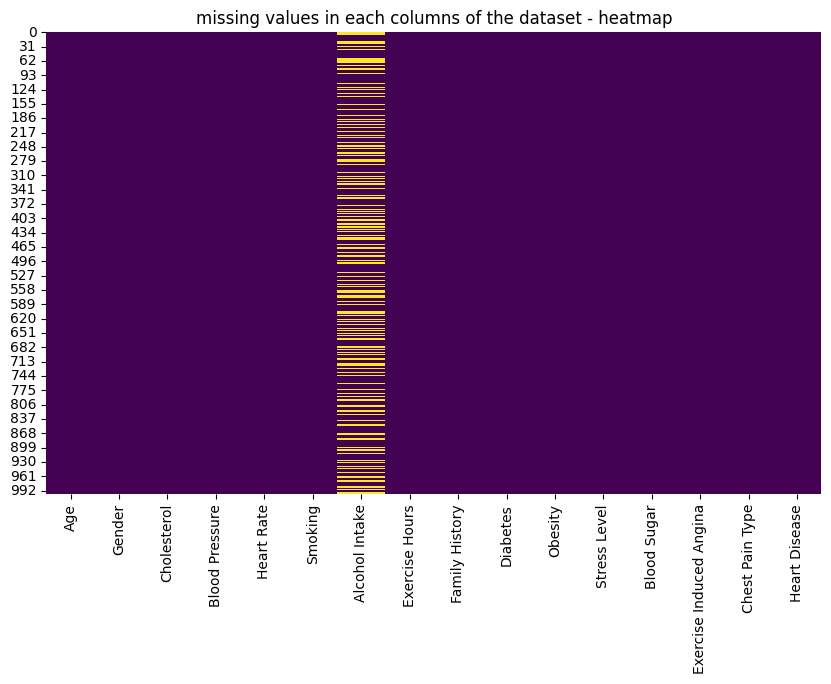

In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(),cmap='viridis',cbar=False)
plt.title('missing values in each columns of the dataset - heatmap')
plt.show()

In [ ]:
df["Alcohol Intake"].value_counts(dropna=False)

,count
Alcohol Intake,
Heavy,346
NaN,340
Moderate,314


In [ ]:
df["Alcohol Intake"].mode()

,Alcohol Intake
0,Heavy


In [ ]:
df["Alcohol Intake"].fillna(
    df["Alcohol Intake"].mode()[0],
    inplace=True
)

In [ ]:
df.isnull().sum()

,0
Age,0
Gender,0
Cholesterol,0
Blood Pressure,0
Heart Rate,0
Smoking,0
Alcohol Intake,0
Exercise Hours,0
Family History,0
Diabetes,0


In [ ]:
df = df.drop_duplicates()

print("Duplicates after removal:")
print(df.duplicated().sum())

Duplicates after removal:
0


In [ ]:
categorical_columns = df.select_dtypes(
    include="object"
).columns

print(categorical_columns)

Index(['Gender', 'Smoking', 'Alcohol Intake', 'Family History', 'Diabetes',
       'Obesity', 'Exercise Induced Angina', 'Chest Pain Type'],
      dtype='object')


In [ ]:
for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())


 Gender
Gender
Female    503
Male      497
Name: count, dtype: int64

 Smoking
Smoking
Never      338
Current    336
Former     326
Name: count, dtype: int64

 Alcohol Intake
Alcohol Intake
Heavy       686
Moderate    314
Name: count, dtype: int64

 Family History
Family History
No     501
Yes    499
Name: count, dtype: int64

 Diabetes
Diabetes
Yes    505
No     495
Name: count, dtype: int64

 Obesity
Obesity
No     501
Yes    499
Name: count, dtype: int64

 Exercise Induced Angina
Exercise Induced Angina
No     528
Yes    472
Name: count, dtype: int64

 Chest Pain Type
Chest Pain Type
Non-anginal Pain    256
Typical Angina      250
Asymptomatic        248
Atypical Angina     246
Name: count, dtype: int64


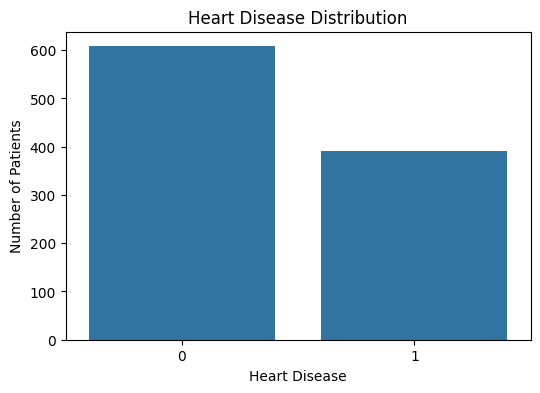

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    x="Heart Disease",
    data=df
)

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Number of Patients")

plt.show()

In [ ]:
print(df["Heart Disease"].value_counts())

Heart Disease
0    608
1    392
Name: count, dtype: int64


In [ ]:
print(
    df["Heart Disease"].value_counts(
        normalize=True
    ) * 100
)

Heart Disease
0    60.8
1    39.2
Name: proportion, dtype: float64


In [ ]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns

print(numerical_columns)

Index(['Age', 'Cholesterol', 'Blood Pressure', 'Heart Rate', 'Exercise Hours',
       'Stress Level', 'Blood Sugar', 'Heart Disease'],
      dtype='object')


In [ ]:
numerical_features = [
    "Age",
    "Cholesterol",
    "Blood Pressure",
    "Heart Rate",
    "Exercise Hours",
    "Stress Level",
    "Blood Sugar"
]

print(numerical_features)

['Age', 'Cholesterol', 'Blood Pressure', 'Heart Rate', 'Exercise Hours', 'Stress Level', 'Blood Sugar']


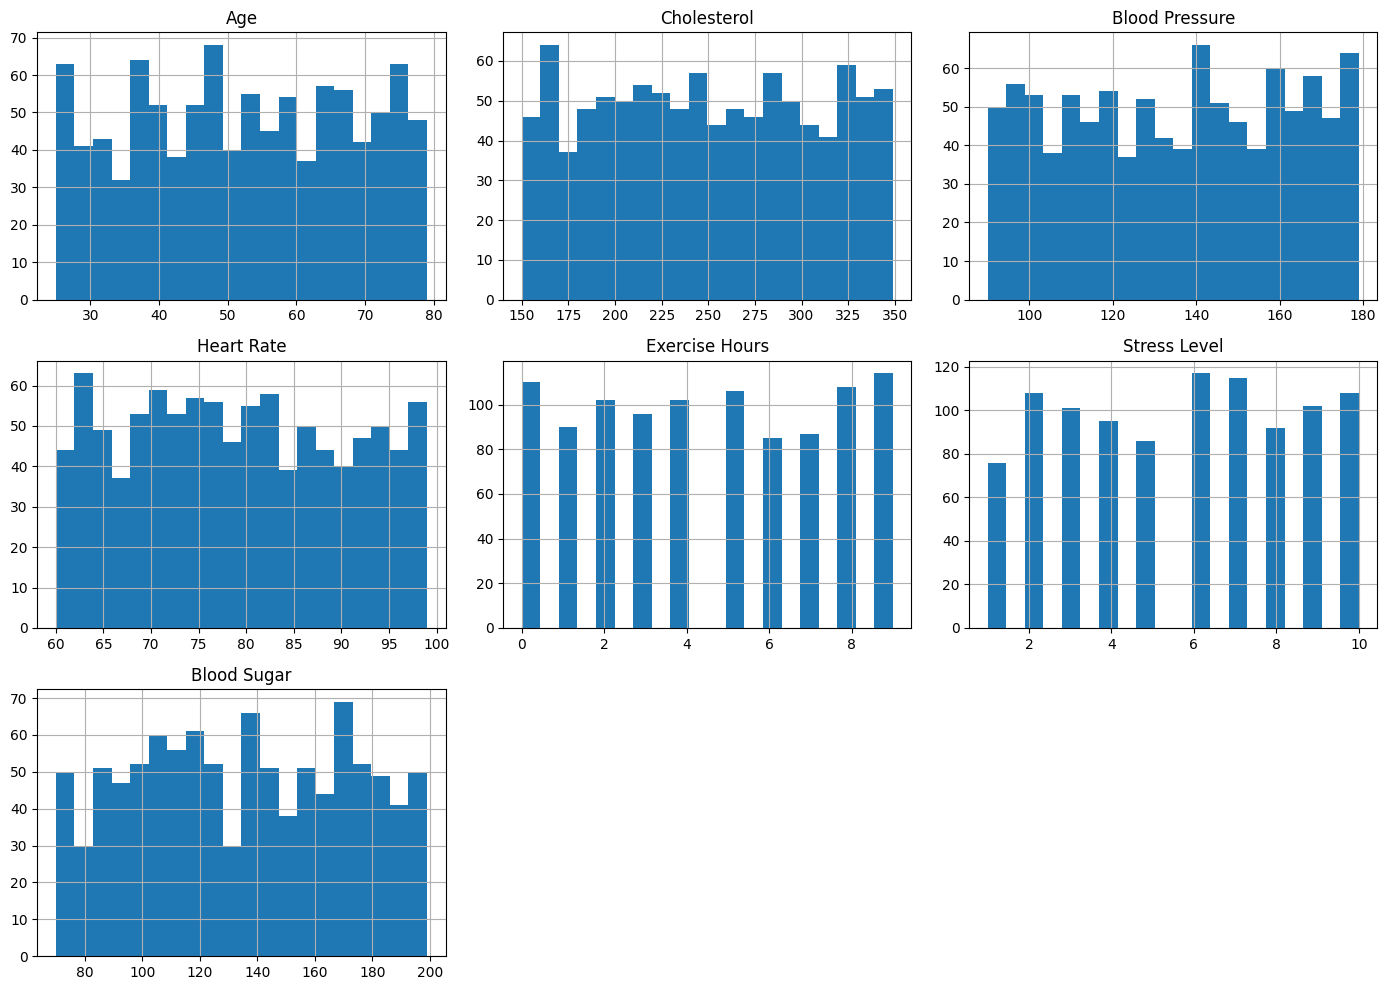

In [ ]:
df[numerical_features].hist(
    figsize=(14,10),
    bins=20
)

plt.tight_layout()
plt.show()

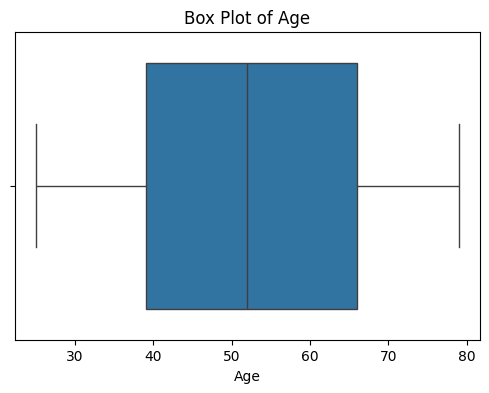

In [ ]:
plt.figure(figsize=(6,4))

sns.boxplot(x=df["Age"])

plt.title("Box Plot of Age")

plt.show()

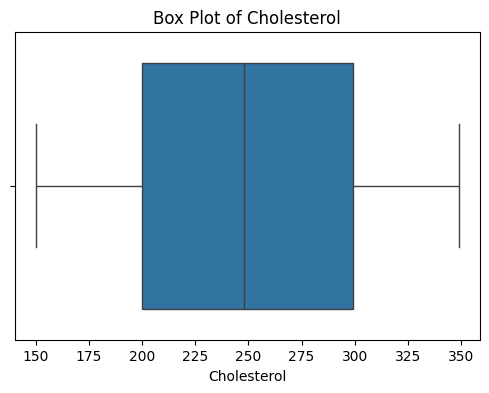

In [ ]:
plt.figure(figsize=(6,4))

sns.boxplot(x=df["Cholesterol"])

plt.title("Box Plot of Cholesterol")

plt.show()

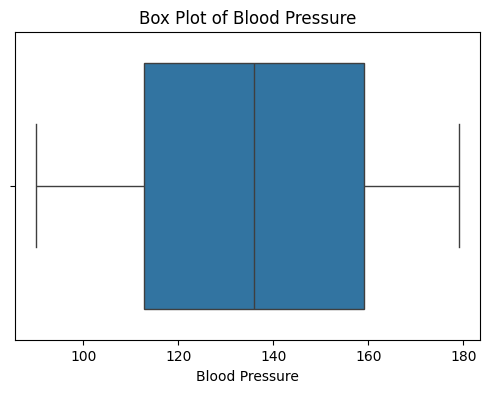

In [ ]:
plt.figure(figsize=(6,4))

sns.boxplot(x=df["Blood Pressure"])

plt.title("Box Plot of Blood Pressure")

plt.show()

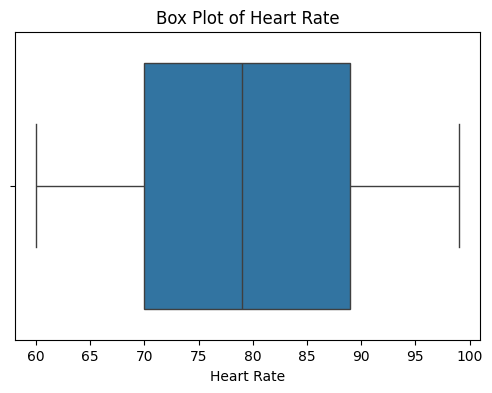

In [ ]:
plt.figure(figsize=(6,4))

sns.boxplot(x=df["Heart Rate"])

plt.title("Box Plot of Heart Rate")

plt.show()

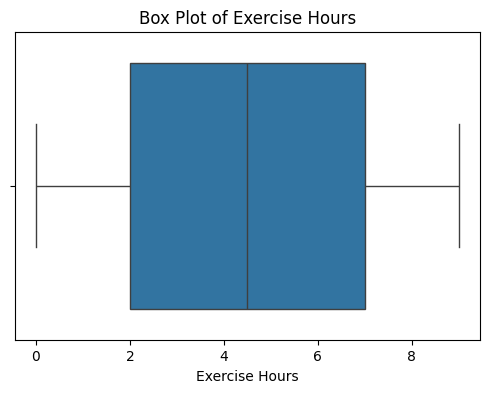

In [ ]:
plt.figure(figsize=(6,4))

sns.boxplot(x=df["Exercise Hours"])

plt.title("Box Plot of Exercise Hours")

plt.show()




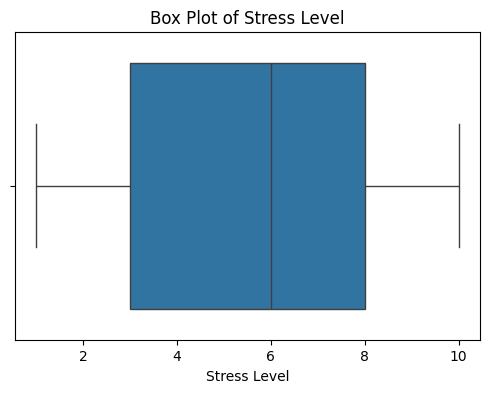

In [ ]:
plt.figure(figsize=(6,4))

sns.boxplot(x=df["Stress Level"])

plt.title("Box Plot of Stress Level")

plt.show()

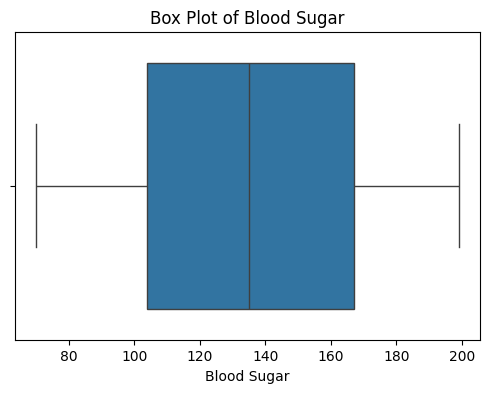

In [ ]:
plt.figure(figsize=(6,4))

sns.boxplot(x=df["Blood Sugar"])

plt.title("Box Plot of Blood Sugar")

plt.show()

In [ ]:
Q1 = df["Cholesterol"].quantile(0.25)
Q3 = df["Cholesterol"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)
print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)

Q1 = 200.0
Q3 = 299.0
IQR = 99.0
Lower Limit = 51.5
Upper Limit = 447.5


In [ ]:
outliers = df[
    (df["Cholesterol"] < lower_limit) |
    (df["Cholesterol"] > upper_limit)
]

print("Number of outliers:", len(outliers))
print(outliers)

Number of outliers: 0
Empty DataFrame
Columns: [Age, Gender, Cholesterol, Blood Pressure, Heart Rate, Smoking, Alcohol Intake, Exercise Hours, Family History, Diabetes, Obesity, Stress Level, Blood Sugar, Exercise Induced Angina, Chest Pain Type, Heart Disease]
Index: []


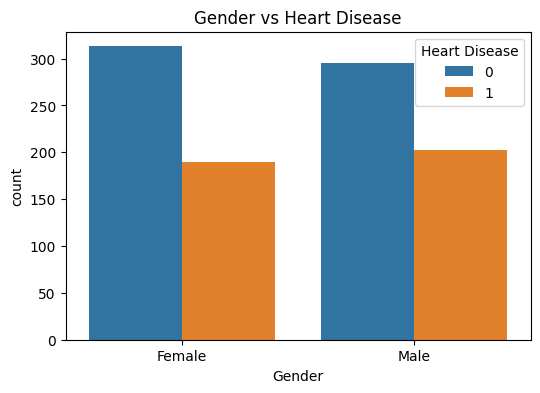

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    x="Gender",
    hue="Heart Disease",
    data=df
)

plt.title("Gender vs Heart Disease")
plt.show()

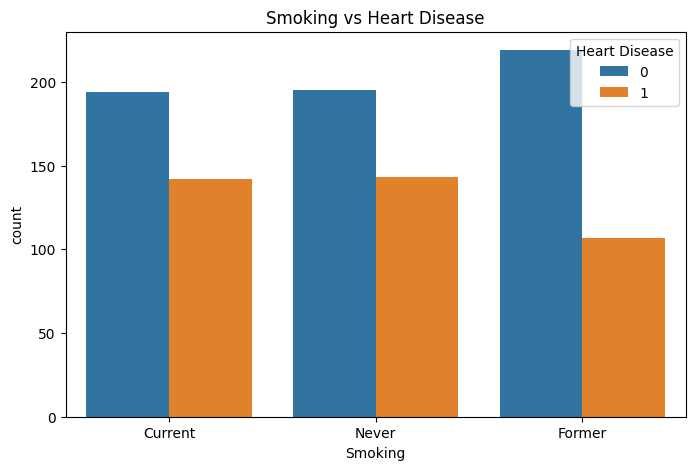

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="Smoking",
    hue="Heart Disease",
    data=df
)

plt.title("Smoking vs Heart Disease")
plt.show()

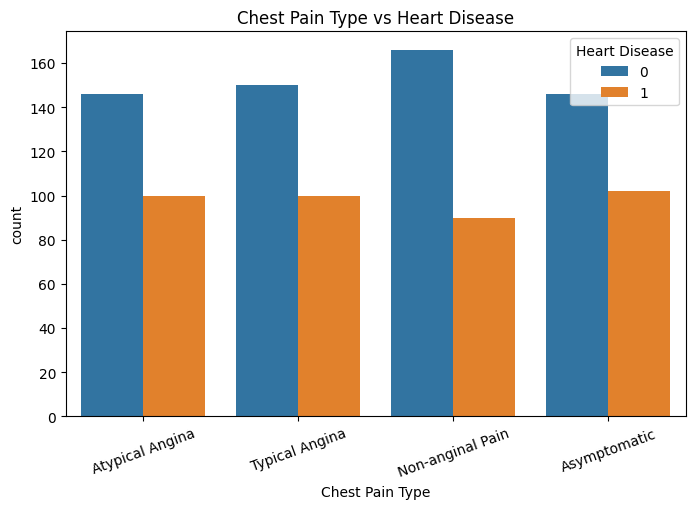

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="Chest Pain Type",
    hue="Heart Disease",
    data=df
)

plt.xticks(rotation=20)
plt.title("Chest Pain Type vs Heart Disease")
plt.show()

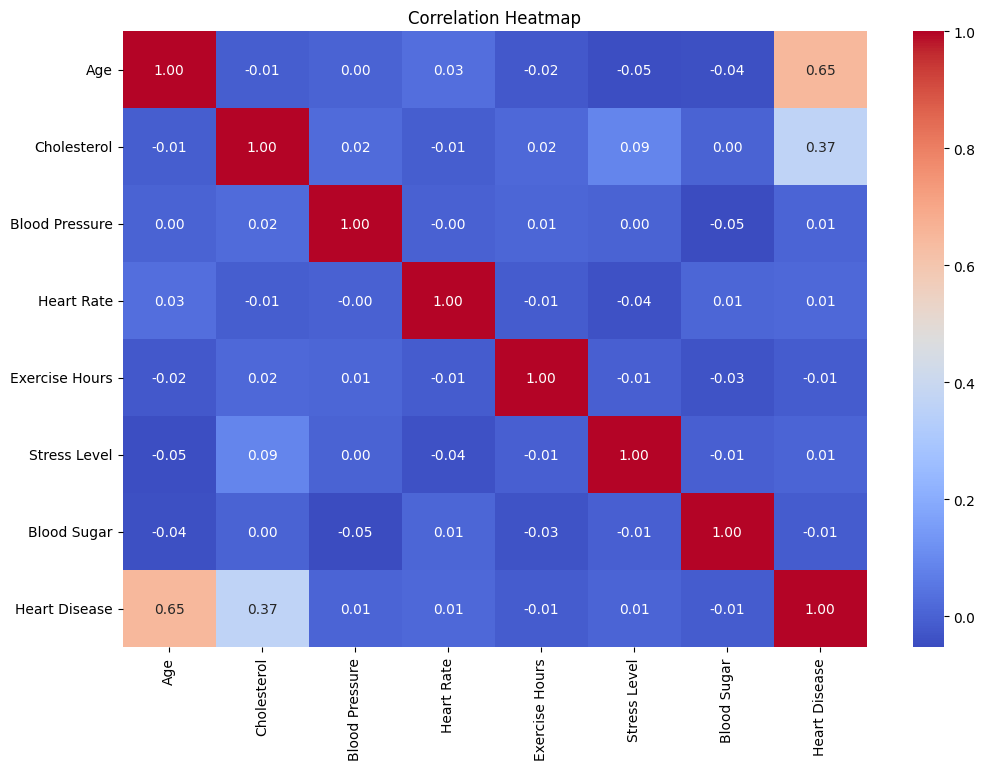

In [ ]:
plt.figure(figsize=(12,8))

correlation = df[
    numerical_features + ["Heart Disease"]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
X = df.drop(
    "Heart Disease",
    axis=1
)

y = df["Heart Disease"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 15)
y shape: (1000,)


In [ ]:
X = pd.get_dummies(
    X,
    drop_first=True
)

print(X.head())

print(
    "Number of features after encoding:",
    X.shape[1]
)

   Age  Cholesterol  Blood Pressure  Heart Rate  Exercise Hours  Stress Level  \
0   75          228             119          66               1             8   
1   48          204             165          62               5             9   
2   53          234              91          67               3             5   
3   69          192              90          72               4             7   
4   62          172             163          93               6             2   

   Blood Sugar  Gender_Male  Smoking_Former  Smoking_Never  \
0          119        False           False          False   
1           70         True           False          False   
2          196         True           False           True   
3          107        False           False          False   
4          183        False           False           True   

   Alcohol Intake_Moderate  Family History_Yes  Diabetes_Yes  Obesity_Yes  \
0                    False               False         False   

In [ ]:
X = X.astype(int)

print(X.head())

   Age  Cholesterol  Blood Pressure  Heart Rate  Exercise Hours  Stress Level  \
0   75          228             119          66               1             8   
1   48          204             165          62               5             9   
2   53          234              91          67               3             5   
3   69          192              90          72               4             7   
4   62          172             163          93               6             2   

   Blood Sugar  Gender_Male  Smoking_Former  Smoking_Never  \
0          119            0               0              0   
1           70            1               0              0   
2          196            1               0              1   
3          107            0               0              0   
4          183            0               0              1   

   Alcohol Intake_Moderate  Family History_Yes  Diabetes_Yes  Obesity_Yes  \
0                        0                   0             0   

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (800, 18)
Testing data: (200, 18)
Training target: (800,)
Testing target: (200,)


In [ ]:
print("Training target distribution:")

print(
    y_train.value_counts(
        normalize=True
    ) * 100
)

print("\nTesting target distribution:")

print(
    y_test.value_counts(
        normalize=True
    ) * 100
)

Training target distribution:
Heart Disease
0    60.75
1    39.25
Name: proportion, dtype: float64

Testing target distribution:
Heart Disease
0    61.0
1    39.0
Name: proportion, dtype: float64


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

print(
    "Training scaled shape:",
    X_train_scaled.shape
)

print(
    "Testing scaled shape:",
    X_test_scaled.shape
)

Training scaled shape: (800, 18)
Testing scaled shape: (200, 18)


In [ ]:
X_train
X_test

,Age,Cholesterol,Blood Pressure,Heart Rate,Exercise Hours,Stress Level,Blood Sugar,Gender_Male,Smoking_Former,Smoking_Never,Alcohol Intake_Moderate,Family History_Yes,Diabetes_Yes,Obesity_Yes,Exercise Induced Angina_Yes,Chest Pain Type_Atypical Angina,Chest Pain Type_Non-anginal Pain,Chest Pain Type_Typical Angina
432,79,222,150,65,6,1,71,1,0,0,1,0,1,1,0,0,0,0
635,28,297,111,94,1,2,183,1,0,1,0,1,1,0,0,1,0,0
478,42,318,118,87,2,8,121,1,0,0,1,1,0,1,1,1,0,0
130,25,224,119,79,3,9,173,1,0,1,0,1,1,1,1,1,0,0
811,68,289,176,70,0,6,129,1,1,0,1,0,0,1,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122,67,328,132,89,6,5,116,1,1,0,0,0,1,0,1,0,0,0
633,49,211,103,73,4,9,127,0,1,0,0,0,0,1,1,1,0,0
602,26,345,122,91,3,9,99,0,1,0,0,0,0,0,0,0,0,0
702,47,305,99,70,5,6,145,0,1,0,1,0,1,0,1,0,1,0


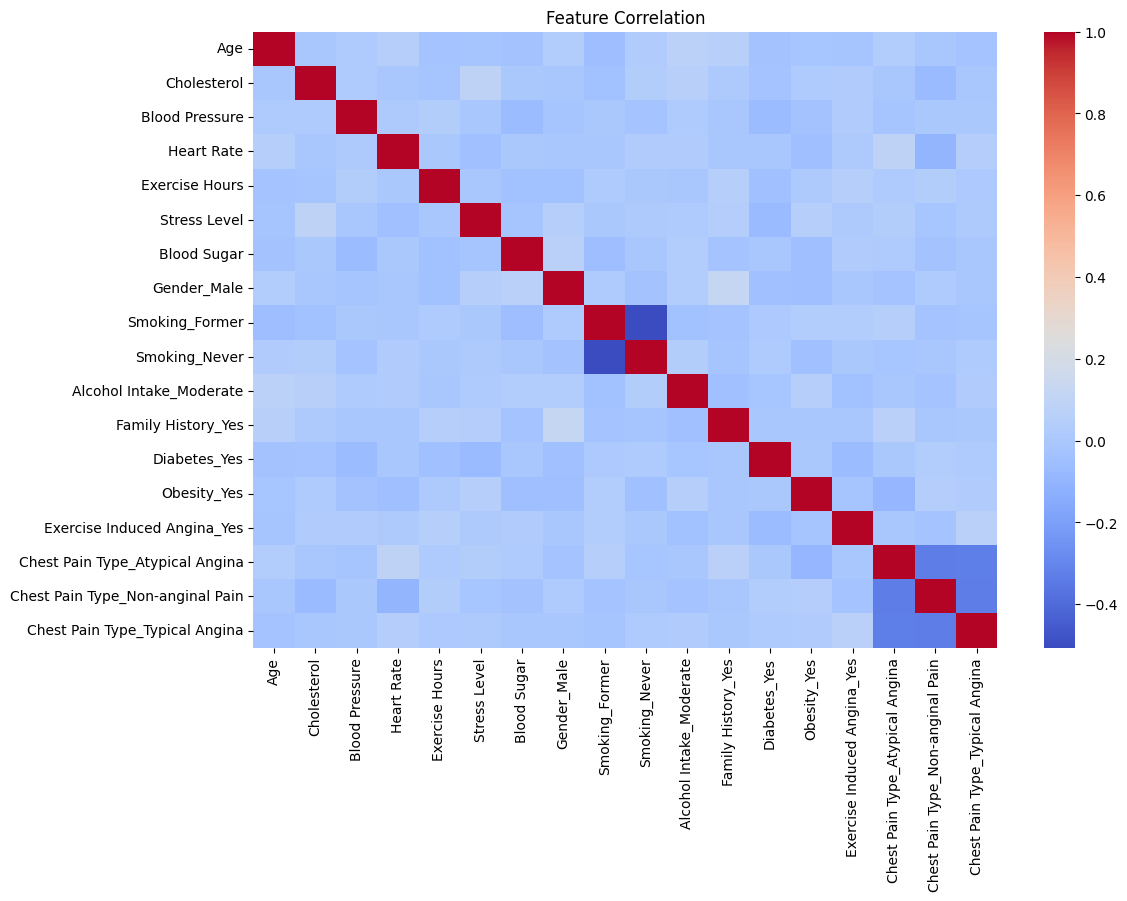

In [ ]:
plt.figure(figsize=(12,8))

corr = X_train.corr()

sns.heatmap(
    corr,
    cmap="coolwarm",
    annot=False
)

plt.title("Feature Correlation")

plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:20])

Predictions:
[1 0 0 0 1 0 1 0 0 0 1 0 0 0 1 1 1 0 0 1]


In [ ]:
result = X_test.copy()

result["Actual Heart Disease"] = y_test.values
result["Predicted Heart Disease"] = y_pred

print(result.head(20))

     Age  Cholesterol  Blood Pressure  Heart Rate  Exercise Hours  \
432   79          222             150          65               6   
635   28          297             111          94               1   
478   42          318             118          87               2   
130   25          224             119          79               3   
811   68          289             176          70               0   
474   64          156              90          67               6   
77    78          223             132          68               7   
637   78          192             146          61               2   
399   37          194             147          81               0   
231   46          262              90          69               9   
323   63          210             136          86               8   
383   49          177             118          60               3   
592   48          214             158          83               8   
714   25          176             

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", accuracy)

print(
    "Accuracy Percentage:",
    accuracy * 100,
    "%"
)

Accuracy: 0.995
Accuracy Percentage: 99.5 %


In [ ]:
from sklearn.metrics import precision_score

precision = precision_score(
    y_test,
    y_pred
)

print("Precision:", precision)

Precision: 1.0


In [ ]:
from sklearn.metrics import recall_score

recall = recall_score(
    y_test,
    y_pred
)

print("Recall:", recall)

Recall: 0.9871794871794872


In [ ]:
from sklearn.metrics import f1_score

f1 = f1_score(
    y_test,
    y_pred
)

print("F1 Score:", f1)

F1 Score: 0.9935483870967742


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.99      1.00      1.00       122
           1       1.00      0.99      0.99        78

    accuracy                           0.99       200
   macro avg       1.00      0.99      0.99       200
weighted avg       1.00      0.99      0.99       200



In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[122   0]
 [  1  77]]


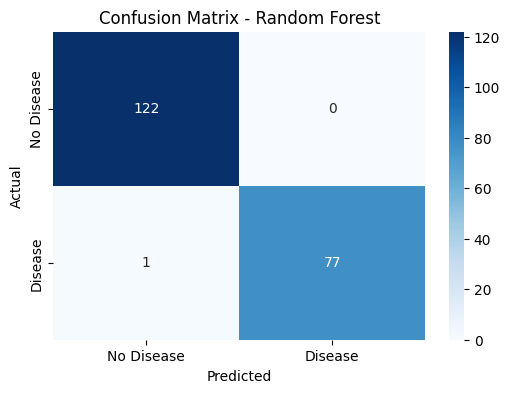

In [ ]:
plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Disease",
        "Disease"
    ],
    yticklabels=[
        "No Disease",
        "Disease"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "Confusion Matrix - Random Forest"
)

plt.show()

Feature Importance

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                             Feature  Importance
0                                Age    0.542526
1                        Cholesterol    0.280289
2                     Blood Pressure    0.030242
3                         Heart Rate    0.029700
6                        Blood Sugar    0.029027
4                     Exercise Hours    0.017898
5                       Stress Level    0.017139
8                     Smoking_Former    0.006740
10           Alcohol Intake_Moderate    0.006071
11                Family History_Yes    0.005699
12                      Diabetes_Yes    0.005482
16  Chest Pain Type_Non-anginal Pain    0.004722
13                       Obesity_Yes    0.004659
7                        Gender_Male    0.004443
14       Exercise Induced Angina_Yes    0.004314
9                      Smoking_Never    0.004180
15   Chest Pain Type_Atypical Angina    0.003858
17    Chest Pain Type_Typical Angina    0.003012


Feature Importance Graph



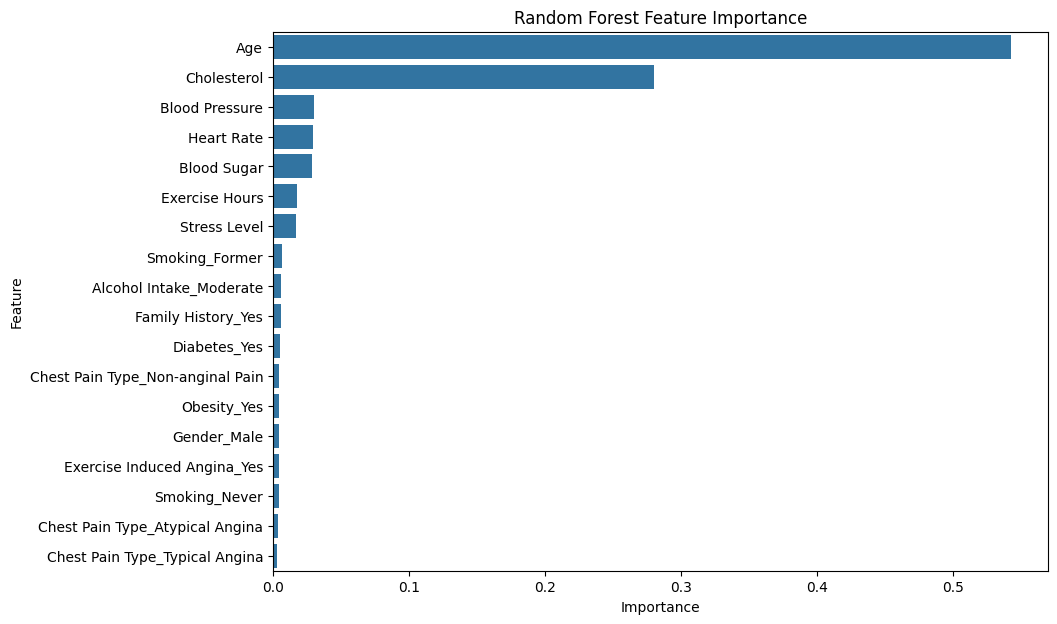

In [ ]:
plt.figure(figsize=(10,7))

sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance
)

plt.title(
    "Random Forest Feature Importance"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

Get prediction probability

In [ ]:
probability = model.predict_proba(
    X_test
)[:, 1]

print("First 10 probabilities:")

print(probability[:10])

First 10 probabilities:
[0.76 0.08 0.05 0.05 0.94 0.11 0.89 0.14 0.01 0.05]


Convert to percentage:

In [ ]:
print(
    probability[:10] * 100
)

[76.  8.  5.  5. 94. 11. 89. 14.  1.  5.]


Create risk category

In [ ]:
def risk_category(probability):

    if probability < 0.30:
        return "Low Risk"

    elif probability < 0.70:
        return "Medium Risk"

    else:
        return "High Risk"

In [ ]:
for p in probability[:10]:

    print(
        "Probability:",
        round(p * 100, 2),
        "%",
        "Risk:",
        risk_category(p)
    )

Probability: 76.0 % Risk: High Risk
Probability: 8.0 % Risk: Low Risk
Probability: 5.0 % Risk: Low Risk
Probability: 5.0 % Risk: Low Risk
Probability: 94.0 % Risk: High Risk
Probability: 11.0 % Risk: Low Risk
Probability: 89.0 % Risk: High Risk
Probability: 14.0 % Risk: Low Risk
Probability: 1.0 % Risk: Low Risk
Probability: 5.0 % Risk: Low Risk


Save the model

In [ ]:
import joblib

joblib.dump(
    model,
    "/content/heart_disease_random_forest.pkl"
)

print("Model saved successfully!")

Model saved successfully!


Save feature names

In [ ]:
feature_names = X.columns.tolist()

joblib.dump(
    feature_names,
    "/content/heart_disease_features.pkl"
)

print("Feature names saved successfully!")

Feature names saved successfully!


Load the saved model

In [ ]:
loaded_model = joblib.load(
    "/content/heart_disease_random_forest.pkl"
)

feature_names = joblib.load(
    "/content/heart_disease_features.pkl"
)

print("Model loaded successfully!")

Model loaded successfully!


Enter a new patient

In [ ]:
age = int(input("Enter Age: "))
gender = input("Enter Gender (Male/Female): ")

cholesterol = int(
    input("Enter Cholesterol: ")
)

blood_pressure = int(
    input("Enter Blood Pressure: ")
)

heart_rate = int(
    input("Enter Heart Rate: ")
)

smoking = input(
    "Enter Smoking (Never/Current/Former): "
)

alcohol = input(
    "Enter Alcohol Intake (Heavy/Moderate): "
)

exercise_hours = int(
    input("Enter Exercise Hours: ")
)

family_history = input(
    "Enter Family History (Yes/No): "
)

diabetes = input(
    "Enter Diabetes (Yes/No): "
)

obesity = input(
    "Enter Obesity (Yes/No): "
)

stress_level = int(
    input("Enter Stress Level: ")
)

blood_sugar = int(
    input("Enter Blood Sugar: ")
)

angina = input(
    "Enter Exercise Induced Angina (Yes/No): "
)

chest_pain = input(
    "Enter Chest Pain Type: "
)


Enter Age: 52
Enter Gender (Male/Female): Female
Enter Cholesterol: 250
Enter Blood Pressure: 150
Enter Heart Rate: 100
Enter Smoking (Never/Current/Former): Former
Enter Alcohol Intake (Heavy/Moderate): Heavy
Enter Exercise Hours: 1
Enter Family History (Yes/No): No
Enter Diabetes (Yes/No): Yes
Enter Obesity (Yes/No): Yes
Enter Stress Level: 70
Enter Blood Sugar: 130
Enter Exercise Induced Angina (Yes/No): No
Enter Chest Pain Type: yes


In [ ]:
blood_sugar = int(
    input("Enter Blood Sugar: ")
)

Enter Blood Sugar: 180


In [ ]:
new_patient = pd.DataFrame({
    "Age": [age],
    "Gender": [gender],
    "Cholesterol": [cholesterol],
    "Blood Pressure": [blood_pressure],
    "Heart Rate": [heart_rate],
    "Smoking": [smoking],
    "Alcohol Intake": [alcohol],
    "Exercise Hours": [exercise_hours],
    "Family History": [family_history],
    "Diabetes": [diabetes],
    "Obesity": [obesity],
    "Stress Level": [stress_level],
    "Blood Sugar": [blood_sugar],
    "Exercise Induced Angina": [angina],
    "Chest Pain Type": [chest_pain]
})

print(new_patient)

   Age  Gender  Cholesterol  Blood Pressure  Heart Rate Smoking  \
0   52  Female          250             150         100  Former   

  Alcohol Intake  Exercise Hours Family History Diabetes Obesity  \
0          Heavy               1             No      Yes     Yes   

   Stress Level  Blood Sugar Exercise Induced Angina Chest Pain Type  
0            70          180                      No             yes  


Encode the new patient

In [ ]:
new_patient = pd.get_dummies(
    new_patient,
    drop_first=True
)

In [ ]:
new_patient = new_patient.reindex(
    columns=feature_names,
    fill_value=0
)

In [ ]:
print(new_patient)
print("Number of features:", new_patient.shape[1])

   Age  Cholesterol  Blood Pressure  Heart Rate  Exercise Hours  Stress Level  \
0   52          250             150         100               1            70   

   Blood Sugar  Gender_Male  Smoking_Former  Smoking_Never  \
0          180            0               0              0   

   Alcohol Intake_Moderate  Family History_Yes  Diabetes_Yes  Obesity_Yes  \
0                        0                   0             0            0   

   Exercise Induced Angina_Yes  Chest Pain Type_Atypical Angina  \
0                            0                                0   

   Chest Pain Type_Non-anginal Pain  Chest Pain Type_Typical Angina  
0                                 0                               0  
Number of features: 18


Make prediction

In [ ]:
prediction = loaded_model.predict(
    new_patient
)[0]

probability = loaded_model.predict_proba(
    new_patient
)[0][1]

Display Final result

In [ ]:
if prediction == 1:

    result = "Heart Disease: Yes"

else:

    result = "Heart Disease: No"

risk = risk_category(probability)

print("\n-----------------------------")
print("Heart Disease Prediction")
print("-----------------------------")

print(result)

print(
    "Risk Probability:",
    round(probability * 100, 2),
    "%"
)

print(
    "Risk Category:",
    risk
)


-----------------------------
Heart Disease Prediction
-----------------------------
Heart Disease: Yes
Risk Probability: 89.0 %
Risk Category: High Risk
